In [1]:
import numpy as np
import pickle

from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel

from particle_filter.plots.plot_results import plot_results
from particle_filter.plots.plot_EES import plot_ESS
from particle_filter.plots.plot_comparisons import plot_comparisons

from particle_filter.simulations import system_simulation

# ESTUDIO DE LA DISCRETIZACIÓN DEL TIEMPO

En este notebook, se va a estudiar el efecto de la discretización del tiempo en el rendimiento de un filtro de partículas. Para ello, se estudiarán los resultados en un péndulo discretizado con el método Euler para distintos $dt$. Dado que el tiempo físico del péndulo es $T= N_{simul} \cdot \Delta t$, se estudirán dos casos:

- Dejando fijo $N_{simul}$ para cada $\Delta t$ lo que mostrará cómo afecta el intervalo temporal entre observacones.

- Manteniendo fijo $T$ y cambiando $\Delta t$, teniendo más mediciones ($N_{simul}$)

El sistema es 

- Vector estado

$$
x_k = \begin{bmatrix}
\theta_k \\
\omega_k
\end{bmatrix}
$$

- Modelo dinámico 

$$
x_{k+1} = \begin{bmatrix}
\theta_k + \omega_k\; \Delta_t \\
\omega_k - \frac{g}{L}\;sin(\theta_k)\;\Delta_t
\end{bmatrix}
+ w_k
$$

- Modelo de medición

$$
y_k = \begin{bmatrix} 1 &0 \end{bmatrix} x_k + v_k
$$

con 

$$
w_k \sim \mathcal{N}(0, Q)\quad \quad v_k \sim \mathcal{N}(0, R)\\\\[2ex]

Q = \begin{bmatrix}

10^{-2}\cdot dt &0\\
0 &10^{-1}\cdot dt
\end{bmatrix}


\quad \quad

R = \begin{bmatrix} 10^{-2} \end{bmatrix}
$$

### Fijo $N_{simul}$

En este primer apartado para un péndulo de longitud $40\;cm$ se van a realizar 150 pasos de simulación. Se va a realizar una simulación con Euler con un diferencial de tiempo muy pequeño ($dt=10^{-4}$) para tomarlo como base de comparación. Los estados se realizan en este caso sin ruido de transición, mientras que las observaciones, que se utilizarán en los próximos filtrados, se obtienen con la incertidumbre especificada en el modelo. 

In [13]:
# Definición función de transición
g = 9.81
L = 0.4
d_true = 0.0001

def f(x):
    theta, omega = x

    omega_dot = -(g / L) * np.sin(theta)

    theta_next = theta + omega * d_true
    omega_next = omega + omega_dot * d_true

    theta_next = (theta_next + np.pi) % (2*np.pi) - np.pi

    return np.array([theta_next, omega_next])

In [59]:
# Definicion funcion de medicion
def h(x):
    theta, _ = x

    return np.array([theta])

In [60]:
# Definicion ruido
Q = np.diag([0.0, 0.0]) #ruido de proceso
R = np.array([0.0]) #ruido de medicion

In [61]:
# Definicion modelos
noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation) 

In [ ]:
T = 15
x0 = np.array([
    np.deg2rad(45), # 45 grados iniciales
    0.0             # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition, observation, x0, T, 0.0001, 0.0001)


with open(f"x_true_2.pkl", "wb") as file:
    pickle.dump(x_true, file)

with open(f"y_obs_2.pkl", "wb") as file:
    pickle.dump(y_obs, file)

In [2]:
with open("x_true.pkl", "rb") as file:
    true_states = pickle.load(file)

with open("y_obs.pkl", "rb") as file:
    observations = pickle.load(file)

In [ ]:
results_bpf_resample = {}
delta_t = [0.01, 0.02, 0.05, 0.1]

# Parametros fijos
g = 9.81
L = 0.4

N_simul = 150
d_true = 0.0001

# Definicion funcion de medicion
def h(x):
    theta, _ = x

    return np.array([theta])

# Modelo de observacion
R = np.array([1e-2]) #ruido de medicion

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation) 

for dt in delta_t:

    # Función de transicion
    def f(x):
        theta, omega = x

        omega_dot = -(g / L) * np.sin(theta)

        theta_next = theta + omega * dt
        omega_next = omega + omega_dot * dt

        theta_next = (theta_next + np.pi) % (2*np.pi) - np.pi

        return np.array([theta_next, omega_next])

    # Ruido de transicion
    Q = np.diag([1e-3 * dt, 1e-2 * dt]) 

    noise_transition = GaussianNoise(Q)
    transition = AdditiveTransitionModel(f, noise_transition)

    y_obs_ratio = int(dt / d_true)
    y_obs_final = int( (N_simul * dt) / d_true)

    y_obs = observations[0:y_obs_final:y_obs_ratio, :]

    bpf = BootstrapParticleFilter(
        N=1000,
        transition_model=transition,
        observation_model=observation
    )

    bpf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

    est_bpf = bpf.run_filter(y_obs, bpf.N/2)

    results_bpf_resample[dt] = est_bpf

    print(f"Diferencial {dt} finalizado")

with open("results_bpf_resample3.pkl", "wb") as file:
    pickle.dump(results_bpf_resample, file)
    

In [3]:
with open("results_bpf_resample.pkl", "rb") as file:
    results_bpf_resample = pickle.load(file)

with open("results_bpf_no_resample.pkl", "rb") as file:
    results_bpf_no_resample = pickle.load(file)

with open("results_apf_no_resample.pkl", "rb") as file:
    results_apf_no_resample = pickle.load(file)

with open("results_apf_resample.pkl", "rb") as file:
    results_apf_resample = pickle.load(file)


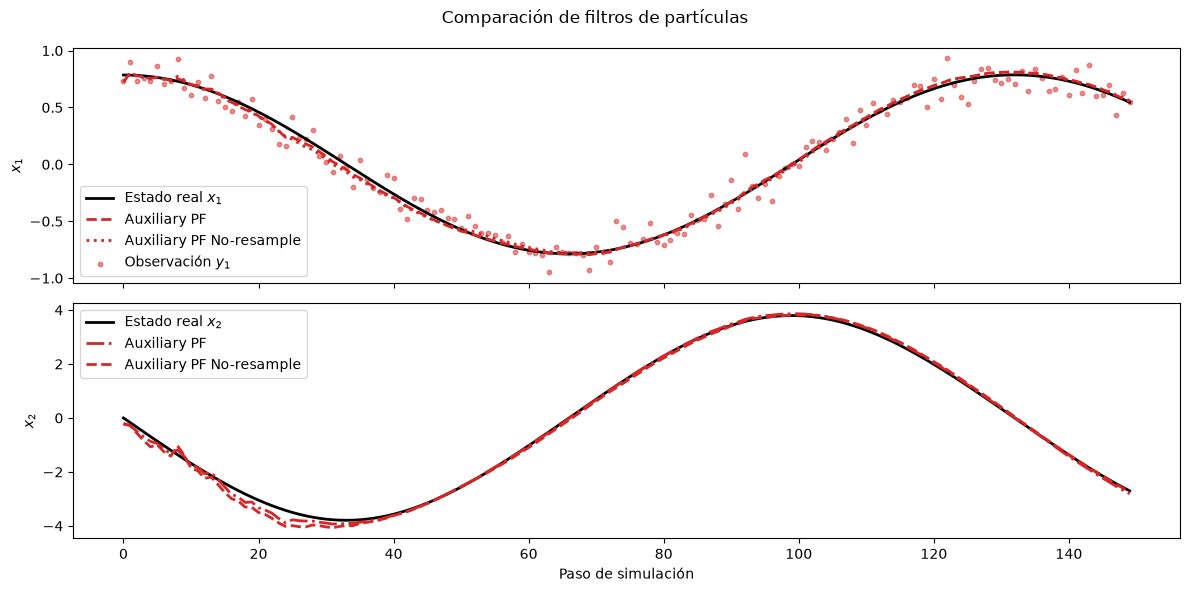

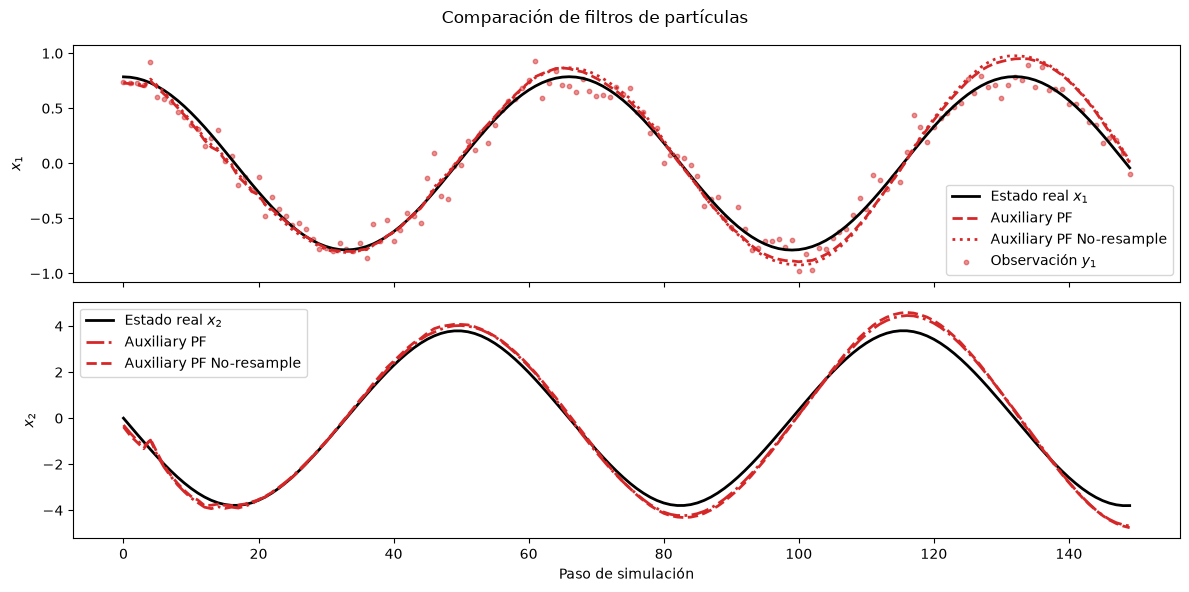

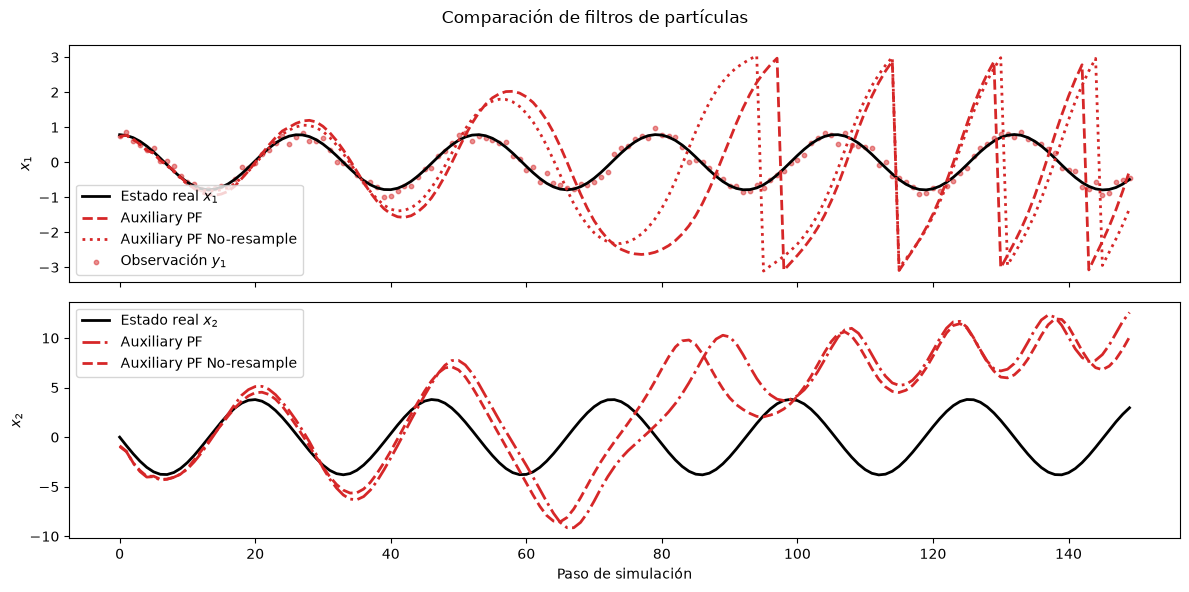

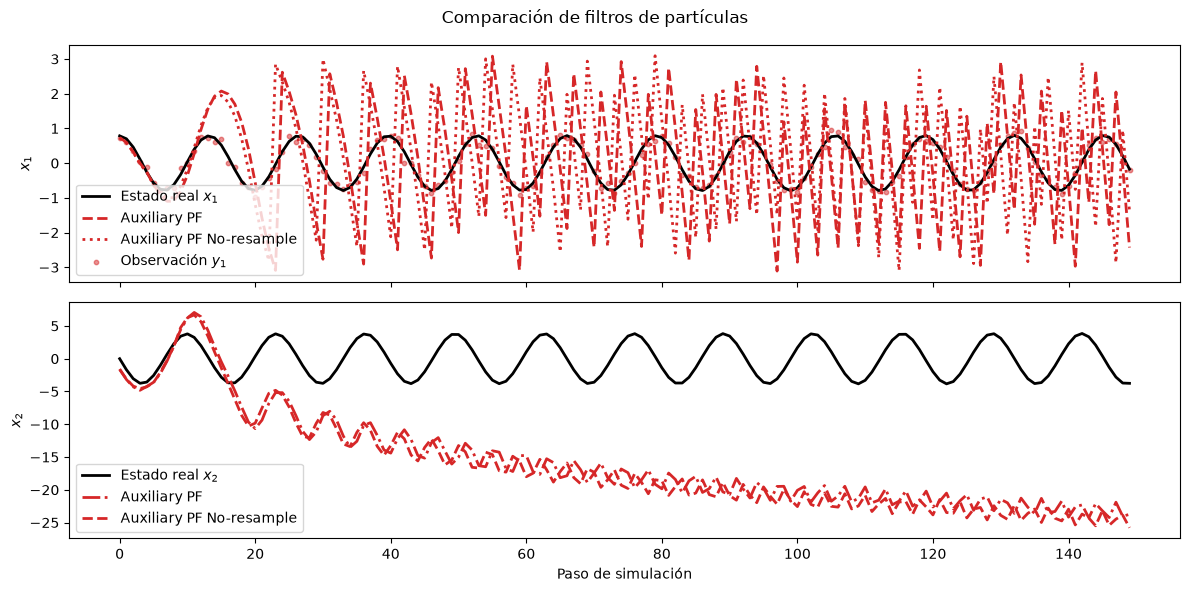

In [10]:
from particle_filter.performance_metrics import RMSE

delta_t = [0.01, 0.02, 0.05, 0.1]

N_simul = 150
d_true = 0.0001

rmse_bpf_no_resample = []
rmse_bpf_resample = []
rmse_apf_no_resample = []
rmse_apf_resample = []

for dt in delta_t:

    ratio= int(dt / d_true)
    final = int( (N_simul * dt) / d_true)

    rmse_bpf_no_resample.append(RMSE(true_states[0:final:ratio, :], results_bpf_no_resample[dt]["estimates"]))
    rmse_bpf_resample.append(RMSE(true_states[0:final:ratio, :], results_bpf_resample[dt]["estimates"]))
    rmse_apf_no_resample.append(RMSE(true_states[0:final:ratio, :], results_apf_no_resample[dt]["estimates"]))
    rmse_apf_resample.append(RMSE(true_states[0:final:ratio, :], results_apf_resample[dt]["estimates"]))

    plot_results(true_states[0:final:ratio, :], observations[0:final:ratio, :], 
                {
                 #"Bootstrap PF": results_bpf_resample[dt]["estimates"],
                 #"Bootstrap PF No-resample": results_bpf_no_resample[dt]["estimates"],
                 "Auxiliary PF": results_apf_resample[dt]["estimates"],
                 "Auxiliary PF No-resample": results_apf_no_resample[dt]["estimates"] 
                  } )

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación del RMSE para distintos diferenciales de tiempo'}, xlabel='Diferencial de tiempo', ylabel='RMSE'>)

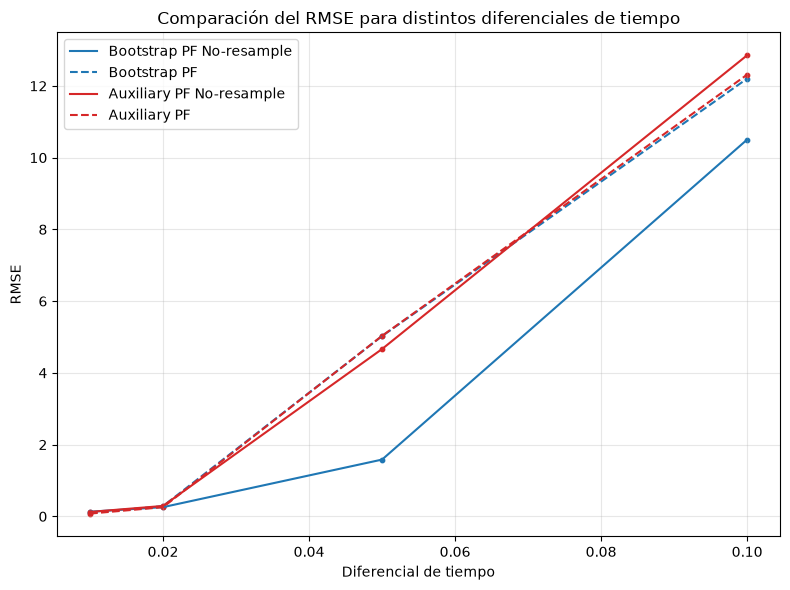

In [5]:
plot_comparisons({
    "Bootstrap PF No-resample": {"Diferencial de tiempo": delta_t, "RMSE": rmse_bpf_no_resample},
    "Bootstrap PF": {"Diferencial de tiempo": delta_t, "RMSE": rmse_bpf_resample},
    "Auxiliary PF No-resample": {"Diferencial de tiempo": delta_t, "RMSE": rmse_apf_no_resample},
    "Auxiliary PF": {"Diferencial de tiempo": delta_t, "RMSE": rmse_apf_resample},
}, "Diferencial de tiempo", "RMSE", "Comparación del RMSE para distintos diferenciales de tiempo")

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación de la log-verosimilitud para distintos diferenciales de tiempo'}, xlabel='Diferencial de tiempo', ylabel='Log-verosimilitud'>)

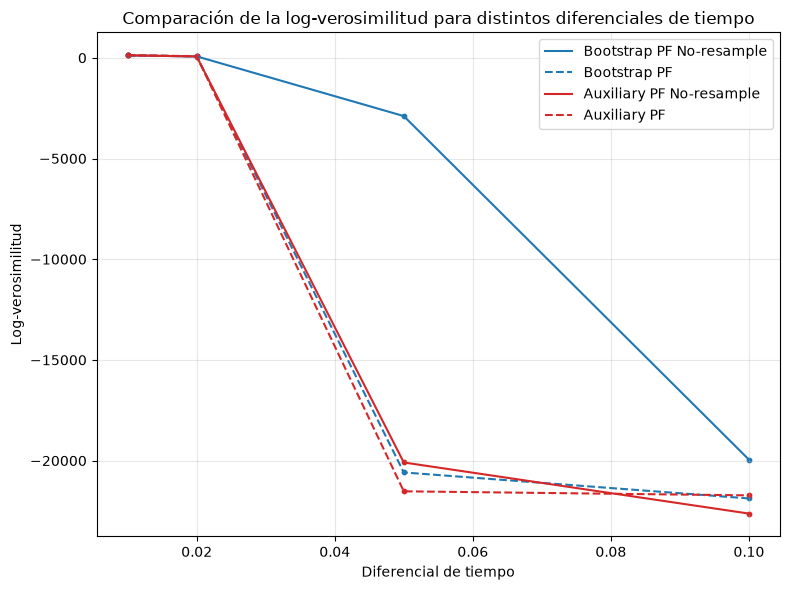

In [15]:
plot_comparisons({
    "Bootstrap PF No-resample": {"Diferencial de tiempo": delta_t, "Log-verosimilitud": [results_bpf_no_resample[dt]["log_likelihood"] for dt in delta_t] },
    "Bootstrap PF": {"Diferencial de tiempo": delta_t, "Log-verosimilitud": [results_bpf_resample[dt]["log_likelihood"] for dt in delta_t] },
    "Auxiliary PF No-resample": {"Diferencial de tiempo": delta_t, "Log-verosimilitud": [results_apf_no_resample[dt]["log_likelihood"] for dt in delta_t] },
    "Auxiliary PF": {"Diferencial de tiempo": delta_t, "Log-verosimilitud": [results_apf_resample[dt]["log_likelihood"] for dt in delta_t] },
}, "Diferencial de tiempo", "Log-verosimilitud", "Comparación de la log-verosimilitud para distintos diferenciales de tiempo")

En este primer experiemento en el que se deja fijo el número de pasos de simulación, a medida que la discretización aumenta, el filtro de partículas pierde rendimiento para seguir el estado real. En este empeoramiento intervienen dos efectos. Primero, cada paso de Euler de la discretización, es "peor", da más saltos de discretización en la dinámica del péndulo. Por otro lado, al tener los mismos pasos de simulación y distintos pasos de discretización, a medida que estos últimos aumentan el sistema aumenta el tiempo físico real que cubre. Estos dos efectos provocan que el sistema debe cubrir más tiempo físico entre observaciones por lo que debe "cubrir" más tiempo sin información del sistema. Esta ausencia de información se va acumulando llevando a los resultados del filtrado a alejarse del sistema real.

El aparente mejor rendimiento del Bootstrap PF sin remuestreo (aunque sigue con un rendimiento malo) puede deberse al hecho de que al no realizar el remuestreo se evita la concentración de partículas y mantiene una mayor diversidad de partículas a costa de una mayor degeneración de pesos.

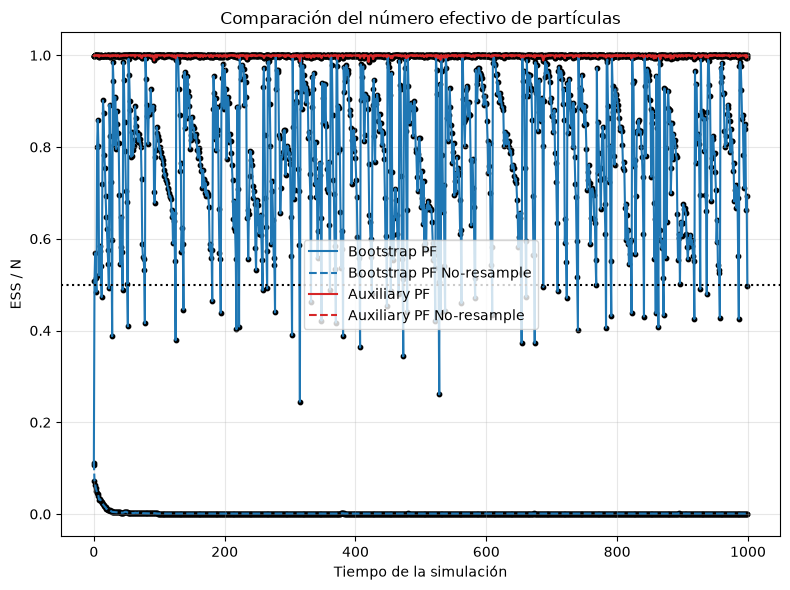

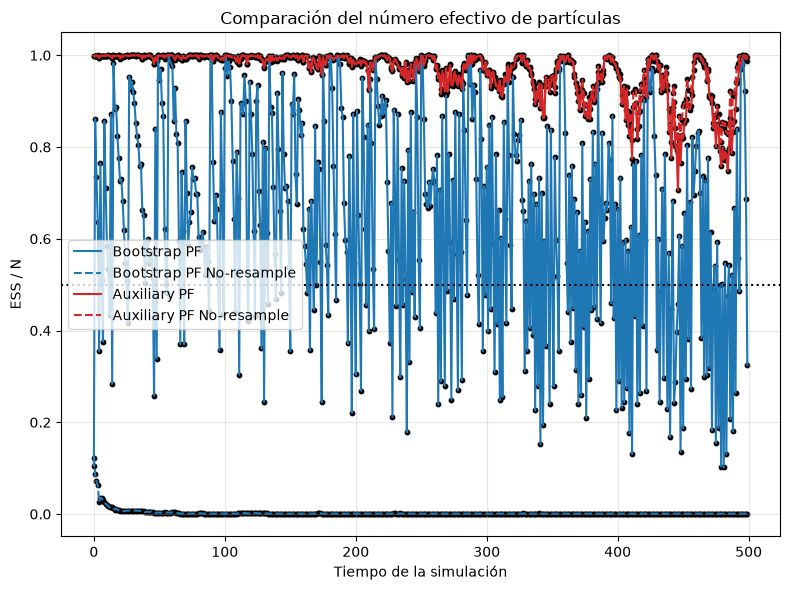

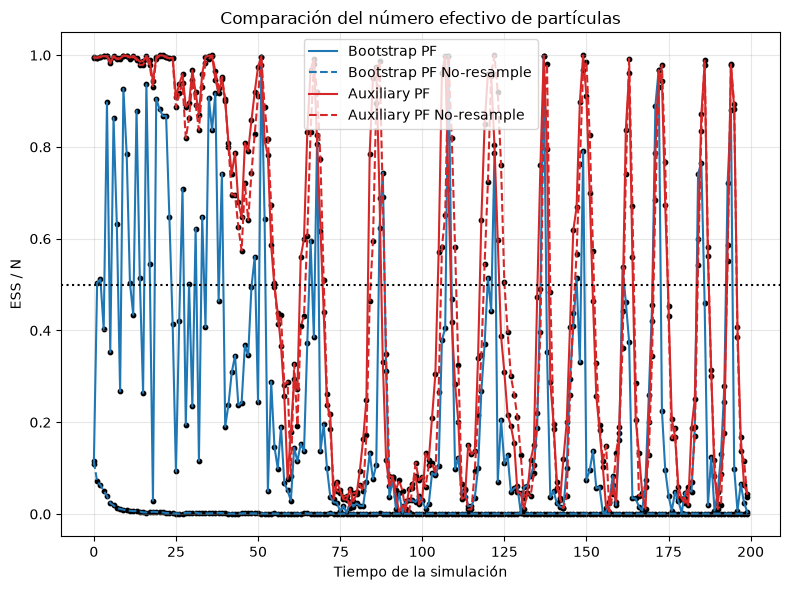

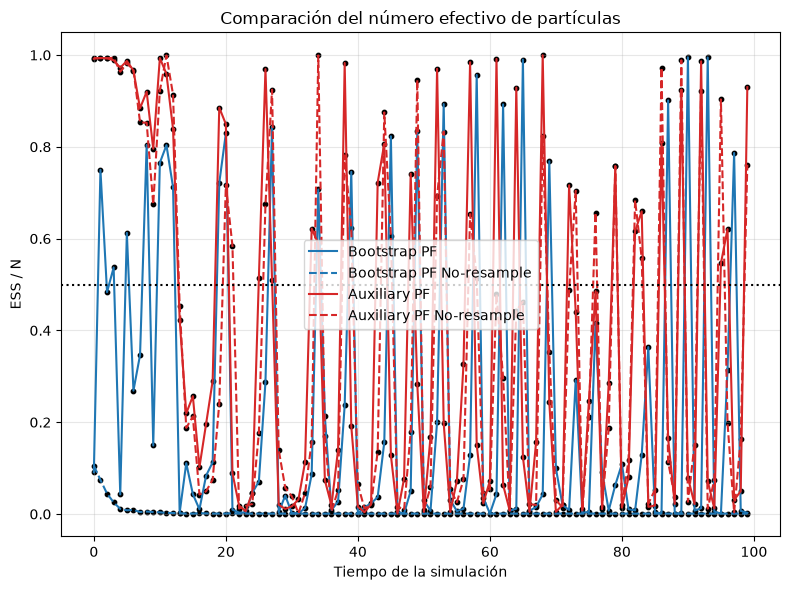

In [ ]:
for dt in delta_t:

    plot_ESS(
        {
            "Bootstrap PF": results_bpf_resample[dt]["normalized_weights"],
            "Bootstrap PF No-resample": results_bpf_no_resample[dt]["normalized_weights"],
            "Auxiliary PF": results_apf_resample[dt]["normalized_weights"],
            "Auxiliary PF No-resample": results_apf_no_resample[dt]["normalized_weights"],
        }
    )

### Fijo $T_{phys}$

Ahora se va a dejar fijo el tiempo de simulación físico del péndulo. En este caso, se adaptará el número de pasos de simulación para cada $dt$ necesarios para cubrir el tiempo físico.

In [17]:
results_bpf_resample = {}
delta_t = [0.01, 0.02, 0.05, 0.1]

# Parametros fijos
g = 9.81
L = 0.4

T = 10
d_true = 0.0001
y_obs_final = int(T / d_true)

# Definicion funcion de medicion
def h(x):
    theta, _ = x

    return np.array([theta])

# Modelo de observacion
R = np.array([1e-2]) #ruido de medicion

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation) 

for dt in delta_t:

    # Función de transicion
    def f(x):
        theta, omega = x

        omega_dot = -(g / L) * np.sin(theta)

        theta_next = theta + omega * dt
        omega_next = omega + omega_dot * dt

        theta_next = (theta_next + np.pi) % (2*np.pi) - np.pi

        return np.array([theta_next, omega_next])

    # Ruido de transicion
    Q = np.diag([1e-3 * dt, 1e-2 * dt]) 

    noise_transition = GaussianNoise(Q)
    transition = AdditiveTransitionModel(f, noise_transition)

    y_obs_ratio = int(dt / d_true)

    y_obs = observations[0:y_obs_final:y_obs_ratio, :]

    bpf = BootstrapParticleFilter(
        N=1000,
        transition_model=transition,
        observation_model=observation  
    )

    bpf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

    est_bpf = bpf.run_filter(y_obs, bpf.N/2)

    results_bpf_resample[dt] = est_bpf

    print(f"Diferencial {dt} finalizado")

with open("results_bpf_resample_exp2_2.pkl", "wb") as file:
    pickle.dump(results_bpf_resample, file)
    

Diferencial 0.01 finalizado
Diferencial 0.02 finalizado
Diferencial 0.05 finalizado
Diferencial 0.1 finalizado


In [4]:

with open("results_bpf_no_resample_exp2.pkl", "rb") as file:
    results_bpf_no_resample = pickle.load(file)

with open("results_bpf_resample_exp2.pkl", "rb") as file:
    results_bpf_resample = pickle.load(file)

with open("results_apf_no_resample_exp2.pkl", "rb") as file:
    results_apf_no_resample = pickle.load(file)

with open("results_apf_resample_exp2.pkl", "rb") as file:
    results_apf_resample = pickle.load(file)


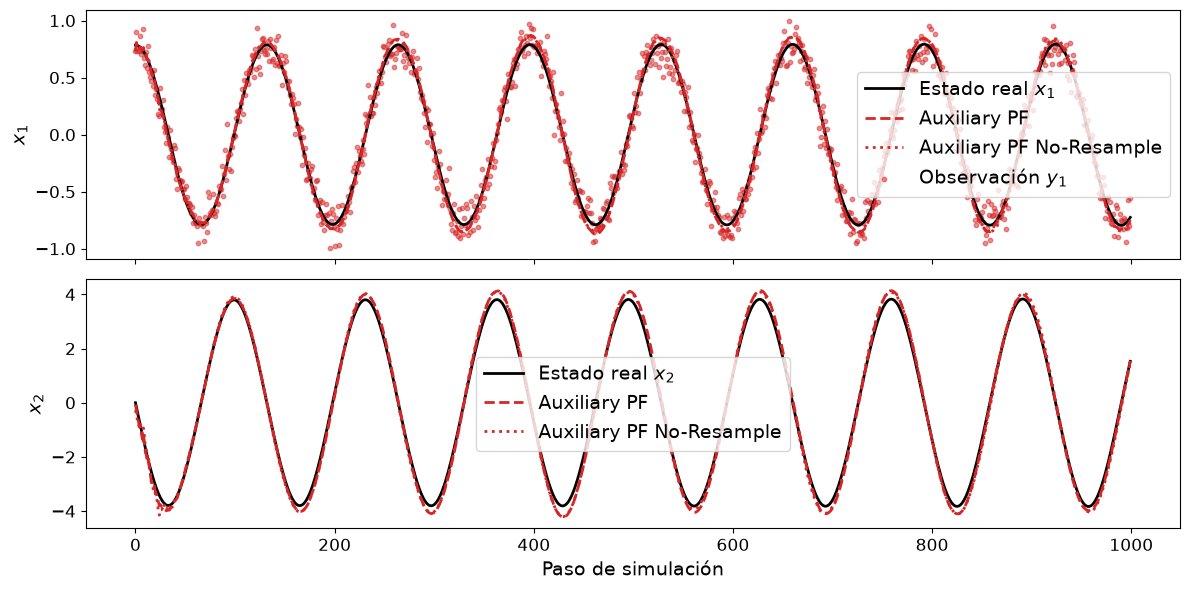

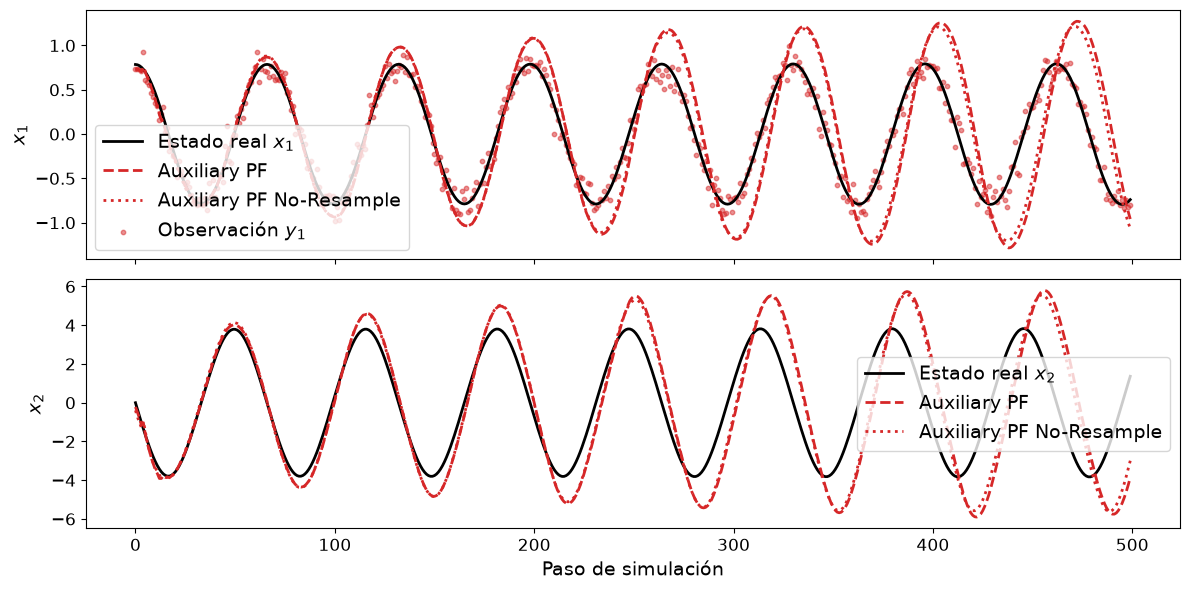

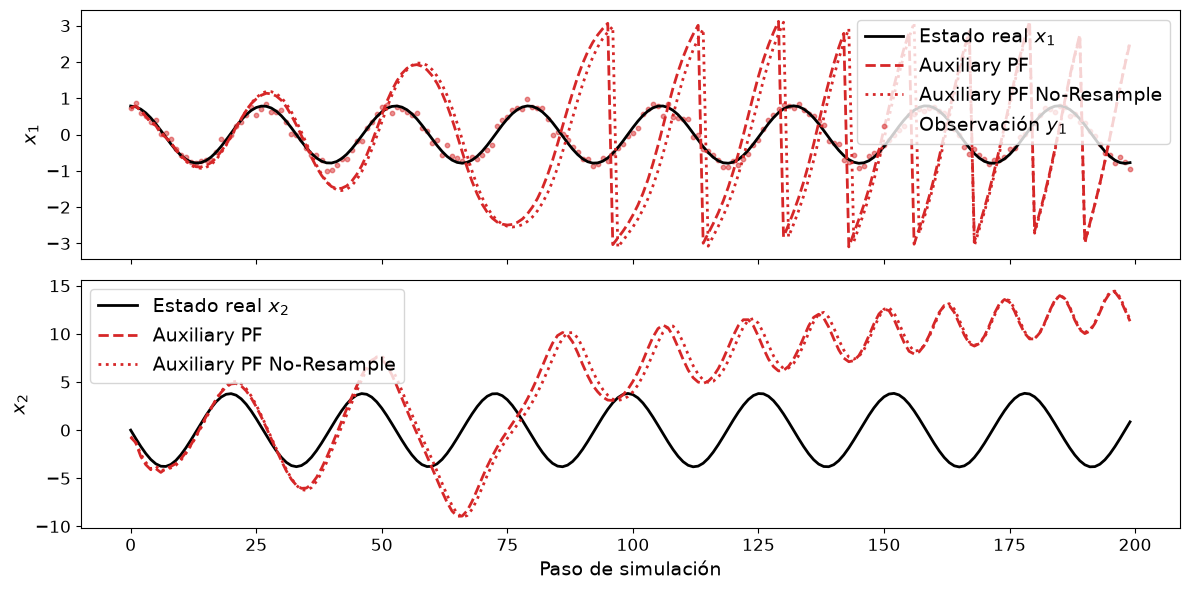

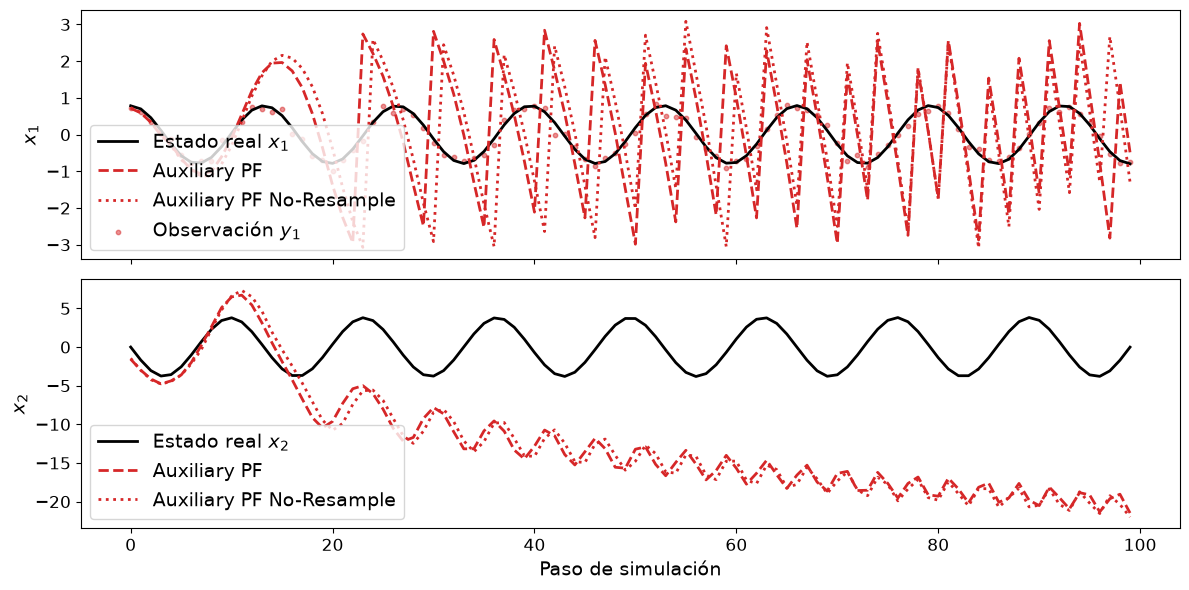

In [7]:
delta_t = [0.01, 0.02, 0.05, 0.1]

T = 10
d_true = 0.0001

rmse_bpf_no_resample = []
rmse_bpf_resample = []
rmse_apf_no_resample = []
rmse_apf_resample = []

for dt in delta_t:

    final = int(T / d_true)
    ratio= int(dt / d_true)

    #rmse_bpf_no_resample.append(RMSE(true_states[0:final:ratio, :], results_bpf_no_resample[dt]["estimates"]))
    #rmse_bpf_resample.append(RMSE(true_states[0:final:ratio, :], results_bpf_resample[dt]["estimates"]))
    #rmse_apf_no_resample.append(RMSE(true_states[0:final:ratio, :], results_apf_no_resample[dt]["estimates"]))
    #rmse_apf_resample.append(RMSE(true_states[0:final:ratio, :], results_apf_resample[dt]["estimates"]))

    plot_results(true_states[0:final:ratio, :], observations[0:final:ratio, :], 
                 {
                 #"Bootstrap PF": results_bpf_resample[dt]["estimates"],
                 "Auxiliary PF": results_apf_resample[dt]["estimates"],
                 #"Bootstrap PF No-Resample": results_bpf_no_resample[dt]["estimates"],
                 "Auxiliary PF No-Resample": results_apf_no_resample[dt]["estimates"] 
                }, x_title="Paso de simulación", plot_title=rf"Evolución del estado estimado ($\Delta t = {dt}$)" )

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación del RMSE para distintos diferenciales de tiempo'}, xlabel='Diferencial de tiempo', ylabel='RMSE'>)

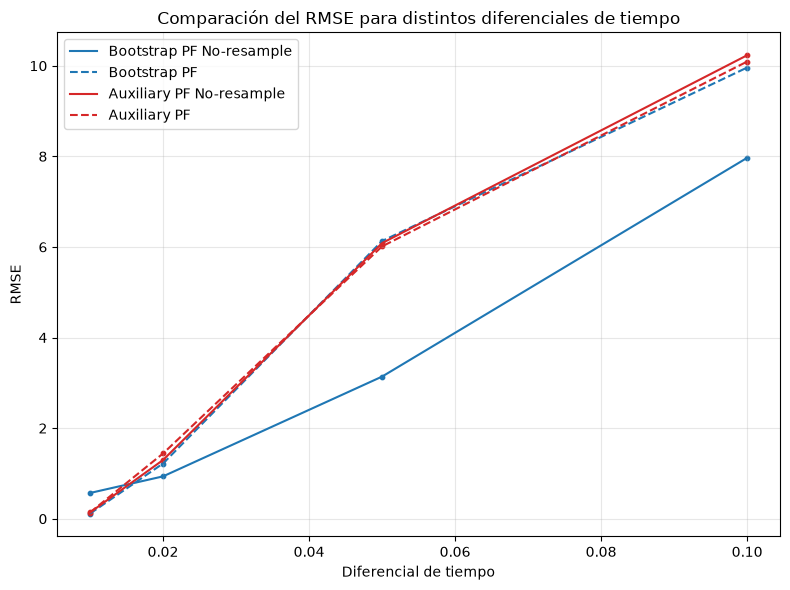

In [18]:
plot_comparisons({
    "Bootstrap PF No-resample": {"Diferencial de tiempo": delta_t, "RMSE": rmse_bpf_no_resample},
    "Bootstrap PF": {"Diferencial de tiempo": delta_t, "RMSE": rmse_bpf_resample},
    "Auxiliary PF No-resample": {"Diferencial de tiempo": delta_t, "RMSE": rmse_apf_no_resample},
    "Auxiliary PF": {"Diferencial de tiempo": delta_t, "RMSE": rmse_apf_resample},
}, "Diferencial de tiempo", "RMSE", "Comparación del RMSE para distintos diferenciales de tiempo")

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación de la log-verosimilitud para distintos diferenciales de tiempo'}, xlabel='Diferencial de tiempo', ylabel='Log-verosimilitud'>)

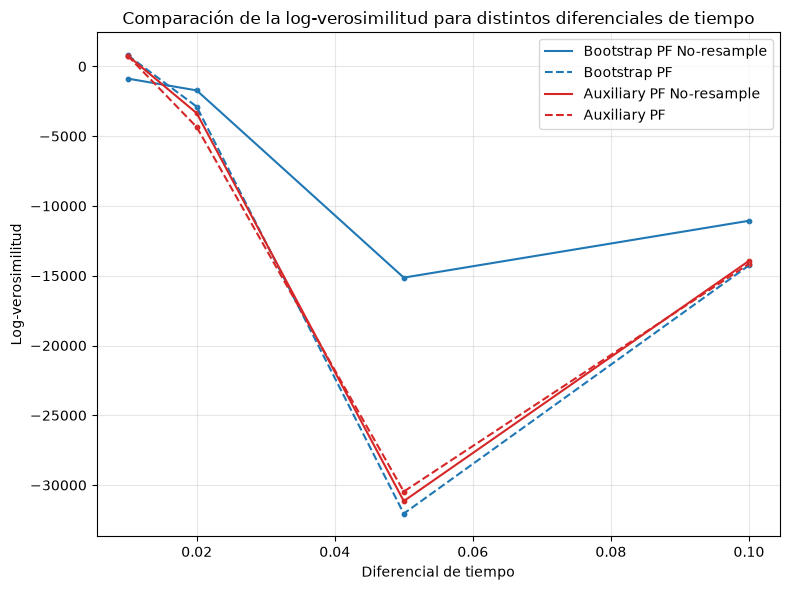

In [19]:
plot_comparisons({
    "Bootstrap PF No-resample": {"Diferencial de tiempo": delta_t, "Log-verosimilitud": [results_bpf_no_resample[dt]["log_likelihood"] for dt in delta_t] },
    "Bootstrap PF": {"Diferencial de tiempo": delta_t, "Log-verosimilitud": [results_bpf_resample[dt]["log_likelihood"] for dt in delta_t] },
    "Auxiliary PF No-resample": {"Diferencial de tiempo": delta_t, "Log-verosimilitud": [results_apf_no_resample[dt]["log_likelihood"] for dt in delta_t] },
    "Auxiliary PF": {"Diferencial de tiempo": delta_t, "Log-verosimilitud": [results_apf_resample[dt]["log_likelihood"] for dt in delta_t] },
}, "Diferencial de tiempo", "Log-verosimilitud", "Comparación de la log-verosimilitud para distintos diferenciales de tiempo")

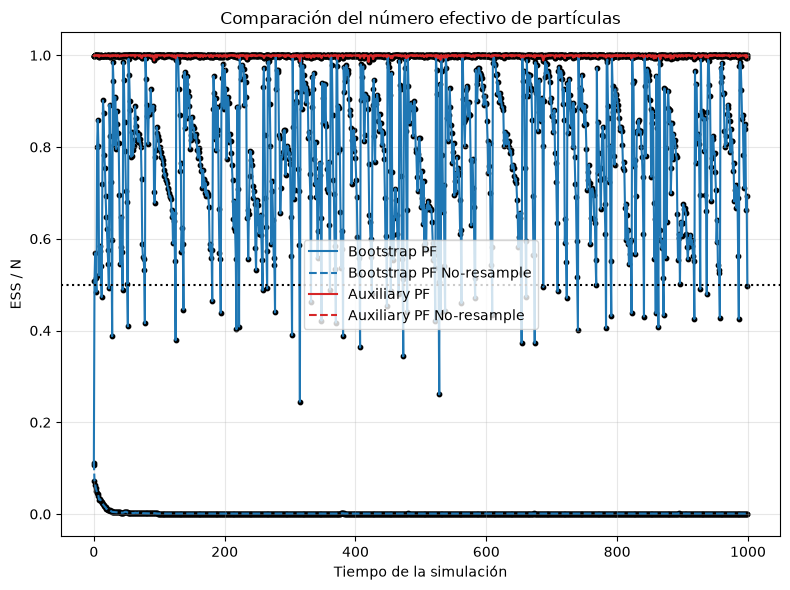

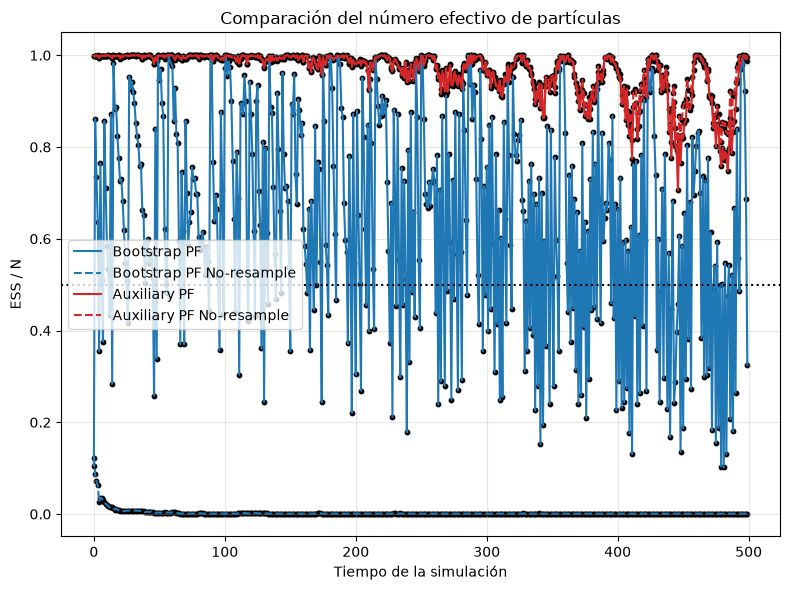

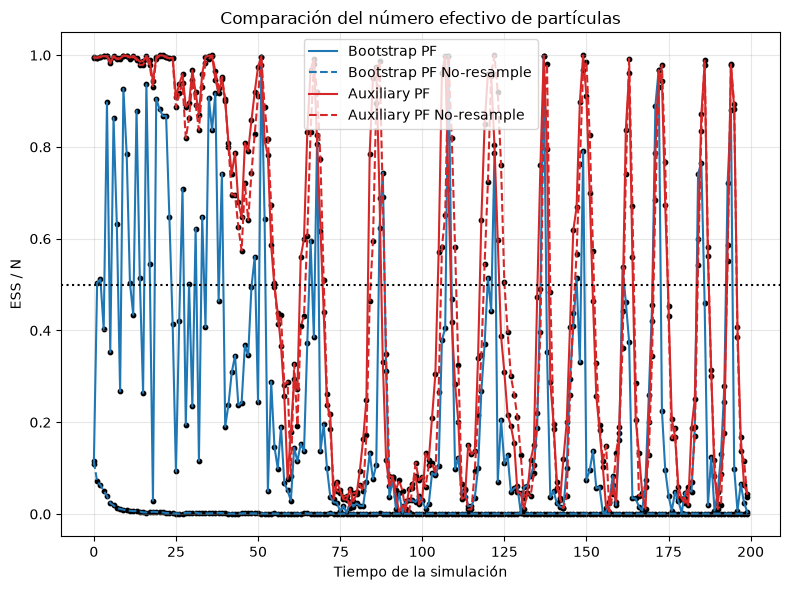

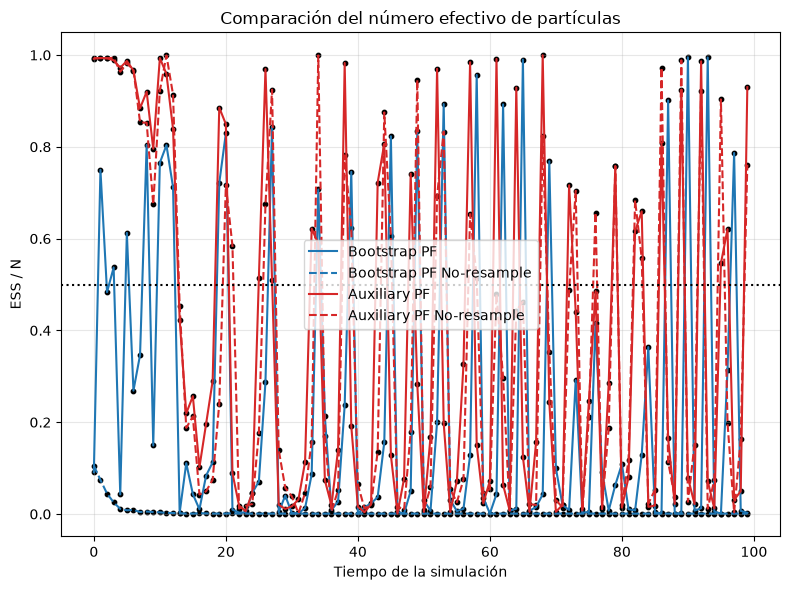

In [30]:
for dt in delta_t:

    plot_ESS(
        {
            "Bootstrap PF": results_bpf_resample[dt]["normalized_weights"],
            "Bootstrap PF No-resample": results_bpf_no_resample[dt]["normalized_weights"],
            "Auxiliary PF": results_apf_resample[dt]["normalized_weights"],
            "Auxiliary PF No-resample": results_apf_no_resample[dt]["normalized_weights"],
        }
    )

En este segundo experimento al fijar el tiempo físico, el error de discretización es más claro. Para cada caso, el tiempo físico de la simulación es el mismo, pero al ir aumentando la discretización, las observaciones están más seperadas y por tanto el filtrado se realiza en tiempos más espaciados. Esto provoca un mayor error en cada propagación que va a aumentando a medida que el sistema avanza. De nuevo, el Bootstap PF sin remuestreo puede parecer más estable porque no está concentrando las partículas por el remuestreo. 